# Introduction to Human Language Technologies
## Lab.4: Part of Speech

### Initialization
Setup the initial dependencies and environment for the exercise.

In [1]:
%pip install nltk python-crfsuite dill matplotlib

import os
import nltk
nltk.download('treebank')
os.makedirs('model', exist_ok=True)
print("Environment initialized and ready for data preparation.")


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Environment initialized and ready for data preparation.


[nltk_data] Downloading package treebank to
[nltk_data]     /Users/omarmoralesortega/nltk_data...
[nltk_data]   Package treebank is already up-to-date!


### 1. Data Preparation
Load the Treebank corpus and split it into the required training chunks and the test set.

In [ ]:
sents = nltk.corpus.treebank.tagged_sents()
train = list(sents[:3000])
test = list(sents[3000:])

### 2. Model Training and Evaluation
Train HMM, TnT, Perceptron, and CRF models for each training size and record their accuracies.

In [ ]:
import os
import time
import dill

accuracies = {
    'HMM': [],
    'TnT': [],
    'Perceptron': [],
    'CRF': []
}
times = {model: {'train': [], 'eval': []} for model in accuracies}

def LID(fd, bins):
  return nltk.probability.LidstoneProbDist(fd, 0.1, bins)

train_sizes = [500, 1000, 1500, 2000, 2500, 3000]

for size in train_sizes:
    print(f"\n--- Training on {size} sentences ---")
    train_sents = train[:size]

    # 1. HMM 
    hmm_model_file = f'model/hmm_model_{size}.dill'
    start = time.perf_counter()
    if os.path.exists(hmm_model_file):
        print(f"Loading HMM from {hmm_model_file}...")
        with open(hmm_model_file, 'rb') as f:
            hmm_tagger = dill.load(f)
    else:
        print("Training HMM...")
        trainer = nltk.tag.hmm.HiddenMarkovModelTrainer()
        hmm_tagger = trainer.train_supervised(train_sents, estimator=LID)
        with open(hmm_model_file, 'wb') as f:
            dill.dump(hmm_tagger, f)
    times['HMM']['train'].append(time.perf_counter() - start)

    start = time.perf_counter()
    accuracies['HMM'].append(hmm_tagger.accuracy(test))
    times['HMM']['eval'].append(time.perf_counter() - start)

    # 2. TnT
    print("Training TnT...")
    start = time.perf_counter()
    tnt_tagger = nltk.tag.tnt.TnT()
    tnt_tagger.train(train_sents)
    times['TnT']['train'].append(time.perf_counter() - start)

    start = time.perf_counter()
    accuracies['TnT'].append(tnt_tagger.accuracy(test))
    times['TnT']['eval'].append(time.perf_counter() - start)

    # 3. Perceptron
    print("Training Perceptron...")
    start = time.perf_counter()
    per_tagger = nltk.tag.PerceptronTagger(load=False)
    per_tagger.train(train_sents)
    times['Perceptron']['train'].append(time.perf_counter() - start)

    start = time.perf_counter()
    accuracies['Perceptron'].append(per_tagger.accuracy(test))
    times['Perceptron']['eval'].append(time.perf_counter() - start)

    # 4. CRF
    print("Training CRF...")
    start = time.perf_counter()
    CRF = nltk.tag.CRFTagger()
    CRF.train(train_sents, 'model/crf_tagger_model')
    times['CRF']['train'].append(time.perf_counter() - start)

    start = time.perf_counter()
    accuracies['CRF'].append(CRF.accuracy(test))
    times['CRF']['eval'].append(time.perf_counter() - start)

    print(f"Results for size {size}:")
    for model in accuracies:
        print(f"  {model:<10} acc={accuracies[model][-1]:.3f}  "
              f"train={times[model]['train'][-1]:.2f}s  eval={times[model]['eval'][-1]:.2f}s")


--- Training on 500 sentences ---
Loading HMM from model/hmm_model_500.dill...
Training TnT...
Training Perceptron...
Training CRF...
Results for size 500:
  HMM        acc=0.794  train=0.00s  eval=1.98s
  TnT        acc=0.910  train=0.04s  eval=0.21s
  Perceptron acc=0.914  train=1.25s  eval=0.38s
  CRF        acc=0.910  train=1.14s  eval=0.05s

--- Training on 1000 sentences ---
Loading HMM from model/hmm_model_1000.dill...
Training TnT...
Training Perceptron...
Training CRF...
Results for size 1000:
  HMM        acc=0.835  train=0.00s  eval=2.12s
  TnT        acc=0.928  train=0.07s  eval=0.21s
  Perceptron acc=0.933  train=2.33s  eval=0.39s
  CRF        acc=0.925  train=2.95s  eval=0.05s

--- Training on 1500 sentences ---
Loading HMM from model/hmm_model_1500.dill...
Training TnT...
Training Perceptron...
Training CRF...
Results for size 1500:
  HMM        acc=0.859  train=0.00s  eval=2.24s
  TnT        acc=0.937  train=0.13s  eval=0.19s
  Perceptron acc=0.941  train=3.39s  eval=0

### 3. Learning Curves
Plot the accuracy of each model against the training set size.

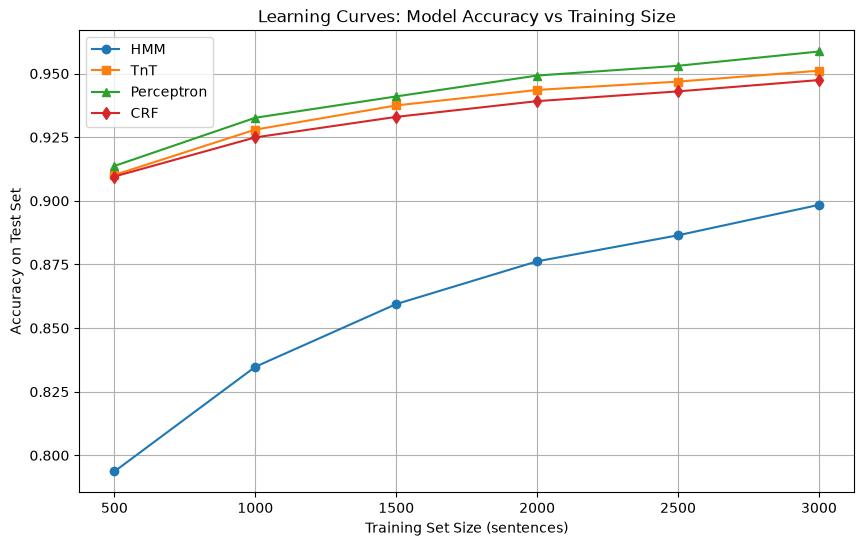

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(train_sizes, accuracies['HMM'], marker='o', label='HMM')
plt.plot(train_sizes, accuracies['TnT'], marker='s', label='TnT')
plt.plot(train_sizes, accuracies['Perceptron'], marker='^', label='Perceptron')
plt.plot(train_sizes, accuracies['CRF'], marker='d', label='CRF')

plt.title('Learning Curves: Model Accuracy vs Training Size')
plt.xlabel('Training Set Size (sentences)')
plt.ylabel('Accuracy on Test Set')
plt.legend()
plt.grid(True)
plt.show()

### 4. Justification
**Which model would you select? Justify the answer.**

We would choose perceptron because it achieves the highest accuracy at every training size, reaching about 95.9% with 3000 sentences while also training faster than CRF on the larger training sets, although CRF tags the test sentences faster.